# Lead–Lag Skill Gym — End-to-End Colab Notebook

**One notebook** for generating nine synthetic time-series families, training nine expert calibrators, learning a 128-dimensional **Mamba + MoE**, training **Actor–Critic PPO with all 12 action types**, running a **regret/solvability/skill-gap curriculum**, and exporting test predictions.

**Direction codes:** `0 = X → Y`, `1 = Y → X`, `2 = bidirectional`, `3 = no direct causal edge`.



**Run each cell top to bottom.** Choose `RUN_MODE='quick'` for a small end-to-end test or `RUN_MODE='full'` for larger experiments. Select GPU in **Runtime → Change runtime type** before using Mamba.

## 0. Packages, Google Drive, and experiment settings

Mount Drive at your existing location. Nothing here overwrites your earlier `Gym/calibrators`, `Gym/mamba_moe`, or PPO checkpoints: this notebook writes into **`Gym/skill_gym_full/`**. `mamba-ssm` must import successfully for `ENCODER='mamba'`; the optional `gru` mode is a diagnostic substitute, not Mamba. See the installation guidance in the note below.

In [ ]:
# Standard scientific dependencies; run once in Colab if missing.
%pip -q install numpy scipy scikit-learn joblib pandas matplotlib nbformat einops

# CUDA Mamba installation is environment-dependent. Verify with:
# from mamba_ssm import Mamba
# If installation is unavailable, switch ENCODER to 'gru' for a smoke test.

In [ ]:
!pip install torch==2.10.0 --index-url https://download.pytorch.org/whl/cu126

Looking in indexes: https://download.pytorch.org/whl/cu126


In [ ]:
import sys
import subprocess
import requests
import torch

print("PyTorch:", torch.__version__)
assert torch.__version__.startswith("2.10.0"), "PyTorch 2.10 required"

abi = "TRUE" if torch.compiled_with_cxx11_abi() else "FALSE"
py = f"cp{sys.version_info.major}{sys.version_info.minor}"

def install_wheel(repo, tag, package):
    api = f"https://api.github.com/repos/{repo}/releases/tags/{tag}"
    response = requests.get(api, timeout=30)
    response.raise_for_status()

    suffix = (
        f"+cu12torch2.10cxx11abi{abi}-"
        f"{py}-{py}-linux_x86_64.whl"
    )

    matches = [
        asset for asset in response.json()["assets"]
        if asset["name"].startswith(package + "-")
        and asset["name"].endswith(suffix)
    ]

    if len(matches) != 1:
        raise RuntimeError(
            f"No matching wheel for {package}: {suffix}"
        )

    subprocess.check_call([
        sys.executable, "-m", "pip", "install",
        "--no-deps", matches[0]["browser_download_url"]
    ])

install_wheel(
    "Dao-AILab/causal-conv1d",
    "v1.6.2.post1",
    "causal_conv1d"
)

install_wheel(
    "state-spaces/mamba",
    "v2.3.2.post1",
    "mamba_ssm"
)

!pip install "mamba-ssm==2.3.2.post1" einops

PyTorch: 2.10.0+cu126
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.5/43.5 MB 30.7 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 48.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.3/29.3 MB 52.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 729.6/729.6 kB 42.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 57.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 89.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 MB 40.9 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 755.0/755.0 kB 46.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [quack-kernels]


In [ ]:
import os, sys, json, math, time, random, copy, warnings
from pathlib import Path
from dataclasses import dataclass
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import joblib
import torch
from torch import nn
from torch.distributions import Categorical
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import balanced_accuracy_score, log_loss
from sklearn.model_selection import StratifiedKFold
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = Path('/content/drive/MyDrive/Aug26/Gym/skill_gym_full')
except ImportError:
    ROOT = Path('./skill_gym_full')
ROOT.mkdir(parents=True, exist_ok=True)
for sub in ('data', 'calibrators', 'models', 'results', 'plots'):
    (ROOT / sub).mkdir(exist_ok=True)

RUN_MODE = os.environ.get('GYM_RUN_MODE', 'full')   # 'quick' or 'full'
ENCODER = os.environ.get('GYM_ENCODER', 'mamba')      # 'mamba' or 'gru'
SEED = 2026
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

CONFIG = {
    'run_mode': RUN_MODE, 'encoder': ENCODER, 'seed': SEED,
    'n_train_per_family': 8 if RUN_MODE == 'quick' else 400,
    'n_val_per_family': 4 if RUN_MODE == 'quick' else 100,
    'n_test_per_family': 4 if RUN_MODE == 'quick' else 100,
    'max_length': 160 if RUN_MODE == 'quick' else 500,
    'min_length': 128 if RUN_MODE == 'quick' else 300,
    'initial_prefix': 80 if RUN_MODE == 'quick' else 160,
    'extend_options': (40, 80) if RUN_MODE == 'quick' else (80, 160),
    'moe_epochs': 2 if RUN_MODE == 'quick' else 25,
    'ppo_epochs': 2 if RUN_MODE == 'quick' else 35,
    'episodes_per_epoch': 18 if RUN_MODE == 'quick' else 512,
    'ppo_update_epochs': 2 if RUN_MODE == 'quick' else 4,
    'max_expert_tests': 3, 'max_steps': 8, 'max_transform_actions': 2,
    'test_cost': 0.008, 'extend_cost': 0.008,
    'transform_cost': 0.004, 'lag_penalty': 0.03,
    'curriculum_rounds': 1 if RUN_MODE == 'quick' else 3,
    'probe_per_condition': 2 if RUN_MODE == 'quick' else 32,
    'new_per_round': 18 if RUN_MODE == 'quick' else 360,
    'curriculum_ppo_epochs': 1 if RUN_MODE == 'quick' else 8,
    'replay_fraction': 0.60,
    'exclude_f8_from_curriculum': True,
}
(ROOT / 'config.json').write_text(json.dumps(CONFIG, indent=2))
print('ROOT =', ROOT, '| device =', DEVICE, '| encoder =', ENCODER, '| mode =', RUN_MODE)
if ENCODER == 'mamba':
    try:
        from mamba_ssm import Mamba
        if DEVICE.type != 'cuda':
            raise RuntimeError('The selected Mamba implementation requires a CUDA GPU.')
        print('Optimized Mamba is installed.')
    except Exception as exc:
        raise RuntimeError('Mamba not available. Install compatible mamba-ssm/causal-conv1d in a CUDA environment, or explicitly set ENCODER="gru" for a diagnostic run.') from exc

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ROOT = /content/drive/MyDrive/Aug26/Gym/skill_gym_full | device = cuda | encoder = mamba | mode = full
Optimized Mamba is installed.


## 1. Generate and save F1–F9 synthetic pairs

The generator uses delayed structural updates, with optional nonlinear links, drifting lag, regime changes, heavy-tailed volatility, irregular observation masks, market-microstructure-like noise, latent confounding (F8), and mixtures (F9). **Ground-truth direction and lag profiles are stored but never provided as Actor observations.** Splits use independent random seeds. For F8, only the `none` structural class is valid; remember the resulting label-family shortcut caveat.

In [ ]:
"""Synthetic lead-lag benchmark generator, F1-F9.

Structural labels describe DIRECT simulated coupling, not observed correlation.
F8 is a latent-common-driver NULL: it may have predictive lead-lag without
any direct X->Y or Y->X causal edge. All lag values are measured in latent
simulation steps, not necessarily number of observed ticks in F6.

Requires NumPy. Each split is independently generated (no pair reuse).
"""
from __future__ import annotations
from dataclasses import dataclass
from pathlib import Path
import numpy as np

DIRECTION = {0: "X_to_Y", 1: "Y_to_X", 2: "both", 3: "none"}
FAMILY = {
    1: "linear_gaussian", 2: "nonlinear", 3: "drifting_lags",
    4: "regime_switching", 5: "heavy_tails_volatility",
    6: "asynchronous_observation", 7: "microstructure_noise",
    8: "latent_common_cause_null", 9: "mixed_mechanisms",
}

@dataclass(frozen=True)
class Config:
    min_length: int = 300
    max_length: int = 500
    burn_in: int = 160
    max_lag: int = 12
    min_lag: int = 2
    seed: int = 2026

    def __post_init__(self):
        assert 32 <= self.min_length <= self.max_length
        assert 1 <= self.min_lag <= self.max_lag
        assert self.burn_in >= 2 * self.max_lag


def _lag_path(rng, n, base, family):
    lag = np.full(n, base, dtype=np.int16)
    if family in (3, 9):
        period = int(rng.integers(70, 150))
        amplitude = int(rng.integers(1, 4))
        t = np.arange(n)
        lag = np.rint(base + amplitude * np.sin(2 * np.pi * t / period)).astype(np.int16)
    return lag


def _innovation(rng, n, family):
    if family in (5, 9):
        # Stationary-ish stochastic volatility with heavy-tailed standardized innovations.
        log_vol = np.zeros(n)
        shocks = rng.normal(0, 0.13, n)
        for t in range(1, n):
            log_vol[t] = 0.95 * log_vol[t-1] + shocks[t]
        z = rng.standard_t(df=4, size=n) / np.sqrt(2.0)
        return np.exp(np.clip(log_vol, -1.2, 1.2)) * z
    return rng.normal(size=n)


def _link(v, family):
    # Bounded nonlinear link prevents explosive feedback under bidirectional coupling.
    if family in (2, 9):
        return np.tanh(1.5 * v) + 0.15 * np.sin(2.0 * v)
    return v


def generate_pair(family: int, direction: int, cfg: Config, rng):
    """Return one labeled episode with observations and underlying lag profiles."""
    if family not in FAMILY or direction not in DIRECTION:
        raise ValueError("family in 1..9 and direction in 0..3 required")
    if family == 8 and direction != 3:
        raise ValueError("F8 is a common-cause NULL; direction must be 3")

    length = int(rng.integers(cfg.min_length, cfg.max_length + 1))
    n = length + cfg.burn_in
    base_xy = int(rng.integers(cfg.min_lag, cfg.max_lag + 1))
    base_yx = int(rng.integers(cfg.min_lag, cfg.max_lag + 1))
    lag_xy = np.clip(_lag_path(rng, n, base_xy, family), 1, cfg.max_lag)
    lag_yx = np.clip(_lag_path(rng, n, base_yx, family), 1, cfg.max_lag)
    active_xy = direction in (0, 2)
    active_yx = direction in (1, 2)

    strength_xy = float(rng.uniform(0.30, 0.65)) if active_xy else 0.0
    strength_yx = float(rng.uniform(0.30, 0.65)) if active_yx else 0.0
    phi_x = float(rng.uniform(0.15, 0.45))
    phi_y = float(rng.uniform(0.15, 0.45))
    noise_x = _innovation(rng, n, family)
    noise_y = _innovation(rng, n, family)
    x = np.zeros(n, dtype=np.float64)
    y = np.zeros(n, dtype=np.float64)
    regime = np.ones(n)
    if family in (4, 9):
        # Switch coupling magnitude, NOT the presence/direction of causal edges.
        switch = int(rng.integers(n // 3, 2 * n // 3))
        regime[switch:] = float(rng.uniform(0.35, 0.65))

    if family == 8:
        # Confounding: two series observe a delayed latent driver; no direct edge.
        z = np.zeros(n + cfg.max_lag + 5)
        eps_z = rng.normal(size=z.size)
        for t in range(1, z.size):
            z[t] = 0.65 * z[t - 1] + eps_z[t]
        dx = int(rng.integers(0, cfg.max_lag + 1))
        dy = int(rng.integers(0, cfg.max_lag + 1))
        for t in range(1, n):
            x[t] = phi_x*x[t-1] + 0.8*z[t + cfg.max_lag - dx] + 0.6*noise_x[t]
            y[t] = phi_y*y[t-1] + 0.8*z[t + cfg.max_lag - dy] + 0.6*noise_y[t]
    else:
        # Structural dynamic simulation: delayed parents are always past values.
        # In 'both' cases, both directed edges exist simultaneously.
        for t in range(1, n):
            cx = 0.0
            cy = 0.0
            if active_yx and t >= lag_yx[t]:
                cx = strength_yx * regime[t] * _link(y[t-lag_yx[t]], family)
            if active_xy and t >= lag_xy[t]:
                cy = strength_xy * regime[t] * _link(x[t-lag_xy[t]], family)
            x[t] = phi_x*x[t-1] + cx + noise_x[t]
            y[t] = phi_y*y[t-1] + cy + noise_y[t]

    x = x[-length:].copy()
    y = y[-length:].copy()
    lag_xy = lag_xy[-length:].copy()
    lag_yx = lag_yx[-length:].copy()

    if family == 7:
        # Observational bid-ask bounce and sporadic outliers; latent dynamics unaffected.
        scale = float(rng.uniform(0.12, 0.4))
        bounce_x = scale * (-1.0)**np.arange(length) * rng.choice([-1, 1])
        bounce_y = scale * (-1.0)**np.arange(length) * rng.choice([-1, 1])
        x += bounce_x + rng.normal(0, 0.12, length)
        y += bounce_y + rng.normal(0, 0.12, length)
        out = rng.random(length) < 0.015
        x[out] += rng.normal(0, 2, out.sum())
        out = rng.random(length) < 0.015
        y[out] += rng.normal(0, 2, out.sum())

    # All observations correspond to physical latent ticks; no value imputation.
    times = np.arange(length, dtype=np.float32)
    mask_x = np.ones(length, dtype=bool)
    mask_y = np.ones(length, dtype=bool)
    if family == 6:
        # Independent irregular event observation times; retain the true timestamps.
        mask_x = rng.random(length) < float(rng.uniform(0.55, 0.85))
        mask_y = rng.random(length) < float(rng.uniform(0.55, 0.85))
        mask_x[0] = mask_y[0] = True
        mask_x[-1] = mask_y[-1] = True

    # Keep raw values. Whole-sequence standardization here would leak
    # future information to an RL agent seeing only a short prefix.
    # Normalize causally in the representation module, using available data.
    x[~mask_x] = np.nan
    y[~mask_y] = np.nan

    # For variable lags, a scalar tau is not valid. Provide complete lag paths.
    # For nulls, no structural lag is defined, despite potential F8 correlation.
    if not active_xy:
        lag_xy[:] = -1
    if not active_yx:
        lag_yx[:] = -1

    return {
        "X": x.astype(np.float32),
        "Y": y.astype(np.float32),
        "t_x": times[mask_x], "t_y": times[mask_y],
        "mask_x": mask_x, "mask_y": mask_y,
        "direction": np.int8(direction), "family": np.int8(family),
        "lag_xy": lag_xy, "lag_yx": lag_yx,
        "length": np.int32(length),
    }


def generate_split(n_per_family: int, cfg: Config, seed: int):
    """Generate episodes with deterministic independent RNG and shuffled order.

    All four directions are balanced within F1-F7 and F9; F8 is all null.
    Consequently the full dataset is not globally class-balanced.
    """
    if n_per_family < 4 or n_per_family % 4:
        raise ValueError("n_per_family must be a positive multiple of 4")
    rng = np.random.default_rng(seed)
    out = []
    for fam in range(1, 10):
        labels = ([3] * n_per_family if fam == 8
                  else np.repeat(np.arange(4), n_per_family // 4).tolist())
        rng.shuffle(labels)
        for d in labels:
            out.append(generate_pair(fam, int(d), cfg, rng))
    rng.shuffle(out)
    return out


def save_split(samples, path: str | Path, cfg: Config):
    """Lossless padded arrays plus masks for variable-length batches; no pickle."""
    n = len(samples)
    T = cfg.max_length
    data = {
        "X": np.full((n, T), np.nan, dtype=np.float32),
        "Y": np.full((n, T), np.nan, dtype=np.float32),
        "mask_x": np.zeros((n, T), dtype=bool),
        "mask_y": np.zeros((n, T), dtype=bool),
        "time": np.full((n, T), np.nan, dtype=np.float32),
        "lag_xy": np.full((n, T), -1, dtype=np.int16),
        "lag_yx": np.full((n, T), -1, dtype=np.int16),
        "length": np.empty(n, dtype=np.int32),
        "direction": np.empty(n, dtype=np.int8),
        "family": np.empty(n, dtype=np.int8),
    }
    for i, s in enumerate(samples):
        l = int(s["length"])
        for key in ("X", "Y", "mask_x", "mask_y", "lag_xy", "lag_yx"):
            data[key][i, :l] = s[key]
        data["time"][i, :l] = np.arange(l)
        for key in ("length", "direction", "family"):
            data[key][i] = s[key]
    np.savez_compressed(path, **data)


def sanity_check(samples, cfg: Config):
    assert all(cfg.min_length <= s["length"] <= cfg.max_length for s in samples)
    for s in samples:
        l = int(s["length"])
        mx, my = s["mask_x"], s["mask_y"]
        assert len(s["X"]) == len(s["Y"]) == l
        assert np.isfinite(s["X"][mx]).all()
        assert np.isfinite(s["Y"][my]).all()
        assert np.isnan(s["X"][~mx]).all()
        assert np.isnan(s["Y"][~my]).all()
        assert len(s["t_x"]) == int(mx.sum())
        assert len(s["t_y"]) == int(my.sum())
        d = int(s["direction"])
        assert (s["lag_xy"] >= 1).all() == (d in (0, 2))
        assert (s["lag_yx"] >= 1).all() == (d in (1, 2))
        if s["family"] == 8:
            assert d == 3

In [ ]:
gen_cfg = Config(min_length=CONFIG['min_length'], max_length=CONFIG['max_length'], seed=SEED)
SPLITS = {}
for split, count, seed in [('train',CONFIG['n_train_per_family'],11),
                            ('val',CONFIG['n_val_per_family'],22),
                            ('test',CONFIG['n_test_per_family'],33)]:
    data = generate_split(count, gen_cfg, seed)
    sanity_check(data, gen_cfg)
    save_split(data, ROOT / 'data' / f'leadlag_{split}.npz', gen_cfg)
    SPLITS[split] = data
    print(split, 'pairs=', len(data), 'classes=', np.bincount([int(z['direction']) for z in data], minlength=4).tolist())

train pairs= 3600 classes= [800, 800, 800, 1200]
val pairs= 900 classes= [200, 200, 200, 300]
test pairs= 900 classes= [200, 200, 200, 300]


## 2. Observation prefixes and representation choices

The environment starts with only an initial prefix. **Extend** reveals additional real observations, while **Transform** changes the representation used for later tests to one of `raw`, `returns`, or `detrend`. The Actor receives a new Mamba representation after either action. No hidden future observation is used in prefix normalization or expert input. Missing samples retain their masks, including F6 irregular sampling.

In [ ]:
REPS = ('raw', 'returns', 'detrend')
EXPERTS = (
    'cross_correlation', 'granger_var', 'transfer_entropy',
    'ccm_proxy', 'hayashi_yoshida_proxy', 'lagged_dtw_proxy',
    'spectral_phase', 'windowed_regimes', 'nonlinear_ridge_proxy'
)
DIRECTION_NAMES = ('X_to_Y', 'Y_to_X', 'both', 'none')

def causal_representation(ep, prefix, representation='raw'):
    """Use ONLY observations at indices < prefix; return [prefix,4] + transformed arrays."""
    p = int(min(prefix, ep['length']))
    px = np.asarray(ep['X'][:p], float).copy()
    py = np.asarray(ep['Y'][:p], float).copy()
    mx = np.asarray(ep['mask_x'][:p], bool)
    my = np.asarray(ep['mask_y'][:p], bool)
    def transform(v, mask):
        inds = np.where(mask & np.isfinite(v))[0]
        if len(inds) < 2:
            return np.zeros(p, dtype=np.float32)
        # All interpolation endpoints are inside the currently visible prefix.
        z = np.interp(np.arange(p), inds, v[inds])
        z = (z - z.mean()) / (z.std() + 1e-6)
        if representation == 'returns':
            z = np.diff(z, prepend=z[0])
        elif representation == 'detrend':
            t = np.arange(p)
            co = np.polyfit(t[inds], z[inds], deg=1)
            z = z - np.polyval(co, t)
        elif representation != 'raw':
            raise ValueError(representation)
        return ((z-z.mean())/(z.std()+1e-6)).astype(np.float32)
    x = transform(px, mx); y = transform(py, my)
    inp = np.stack([x, y, mx.astype(np.float32), my.astype(np.float32)], axis=1)
    assert np.isfinite(inp).all()
    return inp, x, y, mx, my

def neural_batch(ep, prefix, rep):
    z = causal_representation(ep, prefix, rep)[0]
    out = np.zeros((CONFIG['max_length'],4), np.float32)
    out[:len(z)] = z
    return out

## 3. Nine expert statistics + directional lag proposals

Each expert returns **eight raw statistics** and two direction-dependent lag proposals. Every expert is fitted with its *own* four-class logistic calibrator. The library follows our previous experiment's nine expert slots. **Important:** `ccm_proxy`, `hayashi_yoshida_proxy`, `lagged_dtw_proxy`, and `nonlinear_ridge_proxy` are approximations and must be replaced or formally validated before paper claims. The F6 proxy does not constitute a validated Hayashi–Yoshida lead–lag estimator.

In [ ]:
"""Train nine per-expert 4-class calibrators on leadlag_{train,val}.npz.

Exploratory expert library, NOT validated research implementations of CCM,
thermal optimal paths, Hayashi-Yoshida lead-lag estimation, or neural causality.
Those require dedicated algorithmic verification before publication.

Usage:
  pip install numpy scipy scikit-learn joblib
  python train_leadlag_calibrators.py --root /content/drive/MyDrive/Aug26/Gym
  python train_leadlag_calibrators.py --root . --max-train 120 --max-val 60 # smoke test
"""
import argparse
import csv
from pathlib import Path
import warnings
import numpy as np
from scipy.signal import correlate
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, balanced_accuracy_score
import joblib

LAGS = (2, 4, 6, 8, 10, 12)
METHODS = (
    'cross_correlation', 'granger_var', 'transfer_entropy',
    'ccm_proxy', 'hayashi_yoshida_proxy', 'lagged_dtw_proxy',
    'spectral_phase', 'windowed_regimes', 'nonlinear_ridge_proxy'
)


def _paired(x, y):
    ok = np.isfinite(x) & np.isfinite(y)
    return np.asarray(x[ok], float), np.asarray(y[ok], float)


def _norm(v):
    if len(v) < 5:
        return v
    return (v - np.mean(v)) / (np.std(v) + 1e-9)


def _cc(a, b):
    if len(a) < 12 or np.std(a) < 1e-8 or np.std(b) < 1e-8:
        return 0.
    return float(np.clip(np.corrcoef(a, b)[0, 1], -1, 1))


def _directional_arrays(x, y, lag):
    # Past X[t-lag] predicts later Y[t]; and vice versa.
    return x[:-lag], y[lag:], y[:-lag], x[lag:]


def _lagged_correlation(x, y):
    a, b = [], []
    for lag in LAGS:
        x0, y1, y0, x1 = _directional_arrays(x, y, lag)
        a.append(abs(_cc(x0, y1)))
        b.append(abs(_cc(y0, x1)))
    return np.array(a), np.array(b)


def _granger_gain(x, y, lag, nonlinear=False):
    # Out-of-sample prediction gain of target from lagged driver, after
    # controlling for own past. This is an approximation, not a p-value.
    def gain(src, tgt):
        L = max(3, lag)
        if len(src) <= L + 25:
            return 0.
        tt = np.arange(L, len(src))
        own = np.stack([tgt[tt-j] for j in (1, 2, 3)], axis=1)
        other = np.stack([src[tt-lag]], axis=1)
        if nonlinear:
            other = np.column_stack((other, np.tanh(other), other**2))
        a = int(len(tt) * .7)
        if a < 20 or a == len(tt):
            return 0.
        t = tgt[tt]
        r = Ridge(alpha=1.0).fit(own[:a], t[:a]); err0 = np.mean((t[a:]-r.predict(own[a:]))**2)
        f = np.column_stack((own, other))
        r = Ridge(alpha=1.0).fit(f[:a], t[:a]); err1 = np.mean((t[a:]-r.predict(f[a:]))**2)
        return float(np.clip(np.log((err0+1e-8)/(err1+1e-8)), -3, 3))
    return gain(x, y), gain(y, x)


def _cmi_3bin(src, tgt, lag):
    # Histogram conditional mutual information I(src[t-lag];tgt[t] | tgt[t-1]).
    if len(src) < 50 or lag < 1:
        return 0.
    a = np.digitize(src[:-lag], np.quantile(src, [1/3, 2/3]))
    b = np.digitize(tgt[lag:], np.quantile(tgt, [1/3, 2/3]))
    c = np.digitize(tgt[lag-1:-1], np.quantile(tgt, [1/3, 2/3]))
    h = np.zeros((3,3,3), float)
    np.add.at(h, (a,b,c), 1)
    p = h/(h.sum()+1e-12)
    pac = p.sum(axis=1); pbc = p.sum(axis=0); pc = p.sum(axis=(0,1))
    aa, bb, cc = np.nonzero(p)
    q = p[aa,bb,cc]
    return float(np.sum(q * np.log((q * pc[cc]+1e-12)/(pac[aa,cc]*pbc[bb,cc]+1e-12))))


def _ccm_skill(src, target, lag):
    # PROXY: nearest-neighbor cross-map correlation in a delayed embedding.
    # Not full convergent cross mapping: lacks library-size convergence tests.
    if len(src) < 80:
        return 0.
    tt = np.arange(max(2,lag), len(src), 8)
    embed = np.column_stack((target[tt], target[tt-1], target[tt-2]))
    truth = src[tt-lag]
    cut = int(.65 * len(tt))
    if cut < 10 or len(tt)-cut < 5:
        return 0.
    tr = embed[:cut]; te = embed[cut:]
    dist = np.sum((te[:, None, :] - tr[None, :, :])**2, axis=2)
    nn = np.argpartition(dist, kth=min(3,cut-1), axis=1)[:, :min(4,cut)]
    inv = 1/(np.take_along_axis(dist, nn, axis=1)**.5 + .01)
    estimate = (truth[nn]*inv).sum(axis=1)/inv.sum(axis=1)
    return _cc(estimate, truth[cut:])


def _hy_proxy(x, y, mx, my):
    # PROXY: on observed event times, compare lagged nearest-available
    # correlations. It does NOT compute Hayashi-Yoshida covariation.
    ax, ay = x.copy(), y.copy()
    ax[~mx] = np.nan; ay[~my] = np.nan
    fwd=[]; bwd=[]
    for lag in LAGS:
        u, v = ax[:-lag], ay[lag:]; valid=np.isfinite(u)&np.isfinite(v)
        fwd.append(abs(_cc(u[valid],v[valid])))
        u, v = ay[:-lag], ax[lag:]; valid=np.isfinite(u)&np.isfinite(v)
        bwd.append(abs(_cc(u[valid],v[valid])))
    return np.array(fwd),np.array(bwd)


def _dtw_cost(a, b, band=8):
    # Genuine constrained DTW recurrence on downsampled vectors.
    n=len(a); m=len(b); last=np.full(m+1, np.inf);last[0]=0
    for i in range(1,n+1):
        curr=np.full(m+1,np.inf)
        for j in range(max(1,i-band), min(m,i+band)+1):
            curr[j] = abs(a[i-1]-b[j-1]) + min(curr[j-1],last[j],last[j-1])
        last=curr
    return float(last[m]/max(1,n+m))


def _spectral(x,y):
    # Cross-spectral phase gives an approximate lag only for coherent narrowband signals.
    x=x-x.mean(); y=y-y.mean(); n=len(x)
    fx=np.fft.rfft(x);fy=np.fft.rfft(y)
    cross=np.conj(fx)*fy
    f=np.fft.rfftfreq(n)
    keep=(f > .015)&(f < .2)
    if not keep.any():
        return np.zeros(2)
    coh=np.abs(cross[keep])/(np.abs(fx[keep])*np.abs(fy[keep])+1e-9)
    lag = -np.angle(cross[keep])/(2*np.pi*f[keep])
    weight=np.abs(cross[keep])*coh
    score=float(np.average(np.clip(lag,-15,15),weights=weight+1e-12))
    return np.array([max(0.,score)/15., max(0.,-score)/15.])


def _score_expert(name,xraw,yraw,mx,my):
    # Pairwise complete samples are used in most methods. For asynchronous
    # data, this changes the physical lag scale; interpret with caution.
    x,y=_paired(xraw,yraw)
    if len(x)<80: return np.full(8,np.nan)
    x=_norm(x);y=_norm(y)
    if name=='cross_correlation':
        a,b=_lagged_correlation(x,y)
    elif name=='granger_var':
        z=[_granger_gain(x,y,k) for k in LAGS]
        a,b=np.array([v[0] for v in z]),np.array([v[1] for v in z])
    elif name=='transfer_entropy':
        a=np.array([_cmi_3bin(x,y,k) for k in LAGS])
        b=np.array([_cmi_3bin(y,x,k) for k in LAGS])
    elif name=='ccm_proxy':
        a=np.array([_ccm_skill(x,y,k) for k in (2, 6, 10)])
        b=np.array([_ccm_skill(y,x,k) for k in (2, 6, 10)])
    elif name=='hayashi_yoshida_proxy':
        a,b=_hy_proxy(xraw,yraw,mx,my)
    elif name=='lagged_dtw_proxy':
        # DTW is symmetric in its arguments. Fixed-lag shifting creates
        # directional features, but is not a thermal optimal path estimator.
        k=4
        u=np.interp(np.linspace(0,1,50),np.linspace(0,1,len(x)),x)
        v=np.interp(np.linspace(0,1,50),np.linspace(0,1,len(y)),y)
        a=np.array([ -_dtw_cost(u[:-k],v[k:]) ])
        b=np.array([ -_dtw_cost(v[:-k],u[k:]) ])
    elif name=='spectral_phase':
        q=_spectral(x,y);a=np.array([q[0]]);b=np.array([q[1]])
    elif name=='windowed_regimes':
        wins=np.array_split(np.arange(len(x)),4)
        a=[];b=[]
        for w in wins:
            u,v=_lagged_correlation(x[w],y[w]);a.append(np.max(u));b.append(np.max(v))
        a=np.asarray(a);b=np.asarray(b)
    elif name=='nonlinear_ridge_proxy':
        z=[_granger_gain(x,y,k,nonlinear=True) for k in LAGS]
        a,b=np.array([v[0] for v in z]),np.array([v[1] for v in z])
    else:
        raise KeyError(name)
    # Common 8-dimensional method-specific score summaries; no labels used.
    return np.array([np.max(a),np.max(b),np.max(a)-np.max(b),
                     np.mean(a),np.mean(b),np.std(a),np.std(b),
                     len(xraw)/500.],float)

In [ ]:
# We reuse expert-specific raw statistics on the visible, transformed prefix.
# Lags are proposal estimates computed from direction-specific cross-correlation;
# these are NOT calibrated lag predictors.
class EvidenceEngine:
    def __init__(self):
        self.feature_cache = {}
        self.calibrators = {}
        self.fold_calibrators = {}
        self.fold_id = {}
        self.time_record = []
        self.uid_counter = 0

    def raw(self, ep, expert, prefix, rep, cache=True):
        if "_cache_uid" not in ep:
            self.uid_counter += 1
            ep["_cache_uid"] = self.uid_counter
        key = (ep["_cache_uid"], expert, int(prefix), rep)
        if cache and key in self.feature_cache:
            return self.feature_cache[key]
        _, x, y, mx, my = causal_representation(ep, prefix, rep)
        xobs = x.copy(); yobs = y.copy()
        xobs[~mx] = np.nan; yobs[~my] = np.nan
        start = time.perf_counter()
        features = _score_expert(expert, xobs, yobs, mx, my)
        xx = (x - x.mean())/(x.std()+1e-6)
        yy = (y - y.mean())/(y.std()+1e-6)
        corr_xy, corr_yx = [], []
        for k in LAGS:
            if len(x) < k+8: continue
            corr_xy.append(abs(_cc(xx[:-k], yy[k:])))
            corr_yx.append(abs(_cc(yy[:-k], xx[k:])))
        lag_xy = int(LAGS[int(np.argmax(corr_xy))]) if corr_xy else -1
        lag_yx = int(LAGS[int(np.argmax(corr_yx))]) if corr_yx else -1
        elapsed = time.perf_counter() - start
        features = np.asarray(features, float).reshape(8)
        result = (features, (lag_xy, lag_yx), elapsed)
        if cache: self.feature_cache[key] = result
        return result

    def predict(self, ep, expert, prefix, rep, training_oof=False, cache=True):
        raw, lag, seconds = self.raw(ep, expert, prefix, rep, cache=cache)
        art = self.calibrators[expert]
        if training_oof and id(ep) in self.fold_id:
            art = self.fold_calibrators[expert][self.fold_id[id(ep)]]
        med = art['median']
        good = np.isfinite(raw)
        feats = np.r_[np.where(good, raw, med), (~good).astype(float)][None,:]
        probs = art['clf'].predict_proba(feats)[0].astype(np.float32)
        assert np.isfinite(probs).all()
        return probs, lag, seconds

evidence = EvidenceEngine()

## 4. Train nine calibrators, using only training pairs

Each calibrated expert learns \(P(d\mid	ext{statistics})\), where \(d\) is one of the four directions. It sees *all* applicable F1–F9 training conditions. To support RL's **Extend/Transform** actions, fit on multiple partial-prefix/representation conditions. We also build **group-disjoint out-of-fold (OOF) calibrators** for training-time MoE and PPO evidence; the held-out pair is never used to fit the calibrator that predicts it. Saved models go to `calibrators/`.

In [ ]:
train_eps = SPLITS['train']
labels = np.array([int(e['direction']) for e in train_eps])
folds = 2 if RUN_MODE == 'quick' else 5
splitter = StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)
fold_indices = list(splitter.split(np.arange(len(train_eps)), labels))
for fold, (_, held) in enumerate(fold_indices):
    for i in held: evidence.fold_id[id(train_eps[i])] = fold

def calibration_observations(ep):
    n = int(ep['length'])
    first = min(n, CONFIG['initial_prefix'])
    # All transformations appear; one option uses the full observed series.
    return [(first, 'raw'), (min(n, first + CONFIG['extend_options'][0]), 'returns'),
            (n, 'detrend')]

def safe_design(a, median):
    good = np.isfinite(a)
    return np.column_stack([np.where(good,a,median), (~good).astype(float)])

for method in EXPERTS:
    rows=[]; yl=[]; groups=[]
    for i, ep in enumerate(train_eps):
        for p, rep in calibration_observations(ep):
            rows.append(evidence.raw(ep, method, p, rep)[0])
            yl.append(int(ep['direction']))
            groups.append(i)
    rows = np.asarray(rows, float); yl=np.asarray(yl); groups=np.asarray(groups)
    fold_arts=[]
    for fitidx, heldidx in fold_indices:
        mask=np.isin(groups, fitidx)
        med=np.nanmedian(np.where(np.isfinite(rows[mask]),rows[mask],np.nan), axis=0)
        med=np.where(np.isfinite(med),med,0.)
        x=safe_design(rows[mask],med)
        model=make_pipeline(StandardScaler(),LogisticRegression(max_iter=700,class_weight='balanced'))
        model.fit(x,yl[mask])
        assert np.array_equal(model[-1].classes_,np.arange(4))
        fold_arts.append({'clf': model, 'median': med})
    med=np.nanmedian(np.where(np.isfinite(rows),rows,np.nan), axis=0)
    med=np.where(np.isfinite(med),med,0.)
    clf=make_pipeline(StandardScaler(),LogisticRegression(max_iter=700,class_weight='balanced'))
    clf.fit(safe_design(rows,med),yl)
    evidence.calibrators[method]={'clf':clf,'median':med}
    evidence.fold_calibrators[method]=fold_arts
    joblib.dump({'full':evidence.calibrators[method],'oof':fold_arts},
                ROOT/'calibrators'/f'{method}.joblib')
    print(f'{method:28s} trained, samples={len(yl)}',flush=True)
print('Saved all nine calibrators to', ROOT/'calibrators')

cross_correlation            trained, samples=10800
granger_var                  trained, samples=10800
transfer_entropy             trained, samples=10800
ccm_proxy                    trained, samples=10800
hayashi_yoshida_proxy        trained, samples=10800
lagged_dtw_proxy             trained, samples=10800
spectral_phase               trained, samples=10800
windowed_regimes             trained, samples=10800
nonlinear_ridge_proxy        trained, samples=10800
Saved all nine calibrators to /content/drive/MyDrive/Aug26/Gym/skill_gym_full/calibrators


## 5. Supervised Mamba + MoE (128 features → nine weights)

Mamba processes `[X, Y, observed-X mask, observed-Y mask]` and produces a 128-vector. A two-layer MLP gate produces nine expert weights. Frozen calibrated expert probabilities are fused and trained using **four-class negative log likelihood**. For speed, create supervised observations once; for training these use OOF-calibrated predictions. Validation calibrators use full models and validation labels only for measurement. The final Mamba+MoE checkpoint is saved to Drive.

In [ ]:
class SequenceGate(nn.Module):
    def __init__(self, encoder=ENCODER, hidden=128):
        super().__init__()
        self.encoder_name=encoder
        self.embedding=nn.Linear(4,hidden)
        if encoder=='mamba':
            from mamba_ssm import Mamba
            self.backbone=nn.Sequential(
                Mamba(d_model=hidden,d_state=16,d_conv=4,expand=2),
                Mamba(d_model=hidden,d_state=16,d_conv=4,expand=2))
        elif encoder=='gru':
            self.backbone=nn.GRU(hidden,hidden,batch_first=True)
        else: raise ValueError(encoder)
        self.ln=nn.LayerNorm(hidden)
        self.gate=nn.Sequential(nn.Linear(hidden,64),nn.ReLU(),nn.Linear(64,9))

    def encode(self,x,lengths):
        z=self.embedding(x)
        if self.encoder_name=='gru': z,_=self.backbone(z)
        else: z=self.backbone(z)
        pos=torch.arange(x.shape[1],device=x.device)[None,:]
        valid=(pos < lengths[:,None]).float()
        h=(z*valid[:,:,None]).sum(1)/lengths[:,None].clamp(min=1)
        h=self.ln(h)
        g=torch.softmax(self.gate(h),dim=-1)
        return h,g

    def forward(self,x,lengths,expert_probs):
        h,g=self.encode(x,lengths)
        fused=(g[:,:,None]*expert_probs).sum(1).clamp(min=1e-8)
        fused=fused/fused.sum(-1,keepdim=True)
        return fused,g,h

def dense_examples(episodes, *, oof, training):
    seq=[]; length=[]; labels=[]; expert_prob=[]
    for i,ep in enumerate(episodes):
        p=min(int(ep['length']),CONFIG['initial_prefix']) if not training or i%2 else int(ep['length'])
        rep=REPS[i%3] if training else 'raw'
        seq.append(neural_batch(ep,p,rep)); length.append(p)
        labels.append(int(ep['direction']))
        probs=[evidence.predict(ep,name,p,rep,training_oof=oof)[0] for name in EXPERTS]
        expert_prob.append(np.stack(probs))
    return (np.stack(seq).astype(np.float32),np.array(length,dtype=np.int64),
            np.array(labels,dtype=np.int64),np.stack(expert_prob).astype(np.float32))

train_dense=dense_examples(SPLITS['train'],oof=True,training=True)
val_dense=dense_examples(SPLITS['val'],oof=False,training=False)
net=SequenceGate().to(DEVICE)
opt=torch.optim.AdamW(net.parameters(),lr=1e-4 if ENCODER=='mamba' else 4e-4,weight_decay=1e-4)
train_loader=DataLoader(TensorDataset(*[torch.from_numpy(v) for v in train_dense]),
                        batch_size=16 if RUN_MODE=='quick' else 32,shuffle=True)

@torch.no_grad()
def dense_eval(data):
    net.eval(); seq,ln,yl,ep=data
    P=[]
    for i in range(0,len(yl),32):
        x=torch.tensor(seq[i:i+32],device=DEVICE)
        lengths=torch.tensor(ln[i:i+32],device=DEVICE)
        expert=torch.tensor(ep[i:i+32],device=DEVICE)
        pred,_,_=net(x,lengths,expert)
        P.append(pred.cpu().numpy())
    p=np.concatenate(P); return float(log_loss(yl,p,labels=list(range(4)))),float(balanced_accuracy_score(yl,p.argmax(1)))

best_dense=float('inf'); moe_history=[]
for epoch in range(CONFIG['moe_epochs']):
    net.train(); losses=[]
    for x,l,y,expert in train_loader:
        x,l,y,expert=(v.to(DEVICE) for v in (x,l,y,expert))
        pred,_,_=net(x,l,expert)
        loss=-torch.log(pred.gather(1,y[:,None]).clamp(min=1e-8)).mean()
        if not torch.isfinite(loss): raise FloatingPointError('NaN in Mamba+MoE loss')
        opt.zero_grad(); loss.backward();nn.utils.clip_grad_norm_(net.parameters(),1.0);opt.step()
        losses.append(float(loss.item()))
    v_nll,v_bacc=dense_eval(val_dense)
    moe_history.append((epoch+1,np.mean(losses),v_nll,v_bacc))
    print(f'MoE epoch {epoch+1:02d}: train NLL={np.mean(losses):.4f} val NLL={v_nll:.4f} val bAcc={v_bacc:.3f}')
    if v_nll < best_dense:
        best_dense=v_nll
        torch.save({'state_dict':net.state_dict(),'encoder':ENCODER,'config':CONFIG},ROOT/'models'/'best_mamba_moe.pt')
net.load_state_dict(torch.load(ROOT/'models'/'best_mamba_moe.pt',map_location=DEVICE,weights_only=False)['state_dict'])
net.eval()
for p in net.parameters(): p.requires_grad_(False)
pd.DataFrame(moe_history,columns=['epoch','train_nll','val_nll','val_bacc']).to_csv(ROOT/'results'/'moe_history.csv',index=False)

MoE epoch 01: train NLL=1.1779 val NLL=1.1214 val bAcc=0.502
MoE epoch 02: train NLL=1.1376 val NLL=1.1152 val bAcc=0.502
MoE epoch 03: train NLL=1.1359 val NLL=1.1143 val bAcc=0.502
MoE epoch 04: train NLL=1.1361 val NLL=1.1132 val bAcc=0.502
MoE epoch 05: train NLL=1.1222 val NLL=1.1112 val bAcc=0.498
MoE epoch 06: train NLL=1.1129 val NLL=1.0990 val bAcc=0.505
MoE epoch 07: train NLL=1.1101 val NLL=1.0872 val bAcc=0.512
MoE epoch 08: train NLL=1.1043 val NLL=1.0888 val bAcc=0.539
MoE epoch 09: train NLL=1.1038 val NLL=1.0845 val bAcc=0.540
MoE epoch 10: train NLL=1.0992 val NLL=1.0805 val bAcc=0.523
MoE epoch 11: train NLL=1.0972 val NLL=1.0823 val bAcc=0.560
MoE epoch 12: train NLL=1.0929 val NLL=1.0784 val bAcc=0.557
MoE epoch 13: train NLL=1.0947 val NLL=1.0760 val bAcc=0.550
MoE epoch 14: train NLL=1.0925 val NLL=1.0768 val bAcc=0.559
MoE epoch 15: train NLL=1.0924 val NLL=1.0780 val bAcc=0.536
MoE epoch 16: train NLL=1.0916 val NLL=1.0758 val bAcc=0.550
MoE epoch 17: train NLL=

## 6. Full twelve-action RL environment, including parameter choices

**Exactly 12 primary actions:** nine individual expert tests (`0…8`), **Extend** (`9`), **Transform** (`10`), and **Declare** (`11`). Extend has a learned parameter choice (`+40/+80` quick, `+80/+160` full); Transform has a learned choice (`raw/returns/detrend`, excluding the current representation). All actions change the state and incur explicit costs. Expert evidence is computed using only the **currently observed prefix**; no unexecuted expert probabilities enter the Actor's state. Previously collected evidence remains available after a later Extend/Transform. The Actor sees 128 features, nine gate weights, four belief probabilities, nine test flags, plus budget/progress/representation fields.

**Reward:** per-step acquisition costs, and on termination `log P(true direction)` minus a directional lag error penalty. Ground truth is used by the simulator *only for training reward and evaluation*, never for deciding an action.

In [ ]:
EXTEND, TRANSFORM, DECLARE = 9, 10, 11
ACTION_NAMES=EXPERTS+('extend','transform','declare')

class LeadLagEnv:
    def __init__(self,episodes,network,evidence_engine,training=False,config=CONFIG):
        self.episodes=episodes;self.network=network;self.evidence=evidence_engine
        self.training=training;self.cfg=config; self.device=DEVICE
        self.feature_cache={}

    @torch.no_grad()
    def _encode(self):
        key=(id(self.ep),self.prefix,self.rep)
        if key not in self.feature_cache:
            arr=torch.tensor(neural_batch(self.ep,self.prefix,self.rep),device=self.device)[None]
            length=torch.tensor([self.prefix],device=self.device)
            h,g=self.network.encode(arr,length)
            self.feature_cache[key]=(h[0].cpu().numpy(),g[0].cpu().numpy())
        self.h,self.g=self.feature_cache[key]

    def reset(self,ep):
        self.ep=ep;self.prefix=min(self.cfg['initial_prefix'],int(ep['length']))
        self.rep='raw';self.seen=np.zeros(9,dtype=bool);self.results=[]
        self.steps=0;self.n_extend=0;self.n_transform=0
        self.total_cost=0.;self.actual_expert_seconds=0.
        self.done=False;self._encode();self.belief=np.full(4,.25,dtype=np.float32)
        return self.state()

    def _update_belief(self):
        if not self.results:
            self.belief=np.full(4,.25,dtype=np.float32);return
        weights=np.asarray([r['gate_weight'] for r in self.results],dtype=float)
        weights=np.maximum(weights,1e-6);weights/=weights.sum()
        pred=np.sum([w*r['probs'] for w,r in zip(weights,self.results)],axis=0)
        self.belief=(pred/np.sum(pred)).astype(np.float32)

    def state(self):
        onehot=np.zeros(3,np.float32);onehot[REPS.index(self.rep)]=1
        base=np.r_[self.h,self.g,self.belief,self.seen.astype(np.float32),
                   float(self.prefix)/float(self.ep['length']),
                   float(self.total_cost),
                   len(self.results)/max(1,self.cfg['max_expert_tests']),
                   self.steps/max(1,self.cfg['max_steps']),onehot,
                   float(self.n_extend)/2,float(self.n_transform)/max(1,self.cfg['max_transform_actions'])]
        return np.asarray(base,np.float32)

    def legal(self):
        am=np.zeros(12,bool)
        if self.done: return am,np.zeros(2,bool),np.zeros(3,bool)
        if len(self.results)<self.cfg['max_expert_tests']:
            am[:9]=~self.seen
        em=np.array([self.prefix<int(self.ep['length']) for _ in self.cfg['extend_options']],bool)
        # We permit up to two extend decisions; each option is a genuinely different increment.
        if self.n_extend>=2: em[:]=False
        tm=np.array([r!=self.rep for r in REPS],bool)
        if self.n_transform>=self.cfg['max_transform_actions']: tm[:]=False
        am[EXTEND]=em.any();am[TRANSFORM]=tm.any()
        am[DECLARE]=len(self.results)>=1
        if self.steps>=self.cfg['max_steps']-1:
            am[:]=False
            if len(self.results)>=1: am[DECLARE]=True
            else: am[int(np.where(~self.seen)[0][0])]=True
        assert am.any()
        return am,em,tm

    def lag_prediction(self):
        if not self.results: return (-1,-1)
        weights=np.array([max(r['gate_weight'],1e-6) for r in self.results]);weights/=weights.sum()
        def weighted_lag(d):
            vals=np.array([r['lag'][d] for r in self.results])
            ok=vals>=0
            return int(round(np.average(vals[ok],weights=weights[ok]))) if ok.any() else -1
        return weighted_lag(0),weighted_lag(1)

    def terminal_score(self):
        d=int(self.ep['direction'])
        score=float(np.log(max(self.belief[d],1e-8)))
        true_xy=np.asarray(self.ep['lag_xy'],int);true_yx=np.asarray(self.ep['lag_yx'],int)
        lxy,lyx=self.lag_prediction()
        errors=[]
        if d in (0,2) and (true_xy>=0).any() and lxy>=0:
            errors.append(abs(lxy-float(np.median(true_xy[true_xy>=0]))))
        if d in (1,2) and (true_yx>=0).any() and lyx>=0:
            errors.append(abs(lyx-float(np.median(true_yx[true_yx>=0]))))
        lagerr=float(np.mean(errors)) if errors else 0.
        return score-self.cfg['lag_penalty']*lagerr,lagerr

    def step(self,action,parameter=-1):
        am,em,tm=self.legal()
        action=int(action);parameter=int(parameter)
        if action<0 or action>=12 or not am[action]:
            raise ValueError(f'Invalid RL action: {action}')
        reward=0.;self.steps+=1
        if action<9:
            expert=EXPERTS[action]
            probs,lags,elapsed=self.evidence.predict(
                self.ep,expert,self.prefix,self.rep,training_oof=self.training,
                cache=self.training)
            self.results.append({'expert':expert,'probs':probs,'lag':lags,
                                 'prefix':self.prefix,'representation':self.rep,
                                 'gate_weight':float(self.g[action])})
            self.actual_expert_seconds+=elapsed
            self.seen[action]=True
            reward=-self.cfg['test_cost'];self.total_cost+=self.cfg['test_cost']
            self._update_belief()
        elif action==EXTEND:
            if parameter not in (0,1) or not em[parameter]:raise ValueError('Invalid extend option')
            self.prefix=min(int(self.ep['length']),self.prefix+self.cfg['extend_options'][parameter])
            self.n_extend+=1;reward=-self.cfg['extend_cost'];self.total_cost+=self.cfg['extend_cost']
            self._encode()
        elif action==TRANSFORM:
            if parameter not in (0,1,2) or not tm[parameter]:raise ValueError('Invalid transform option')
            self.rep=REPS[parameter];self.n_transform+=1
            reward=-self.cfg['transform_cost'];self.total_cost+=self.cfg['transform_cost']
            self._encode()
        else:
            terminal,lagerr=self.terminal_score()
            reward=terminal;self.done=True
        info={}
        if self.done:
            info={'true':int(self.ep['direction']),'pred':int(self.belief.argmax()),
                  'probs':self.belief.copy(),'lag_pred':self.lag_prediction(),
                  'n_tests':len(self.results),'n_extend':self.n_extend,
                  'n_transform':self.n_transform,'prefix':self.prefix,
                  'cost':self.total_cost,'lag_mae':lagerr,
                  'expert_seconds':self.actual_expert_seconds,
                  'actions':[r['expert'] for r in self.results]}
        return self.state(),float(reward),bool(self.done),info

# Test that each action type changes the state/observation as intended.
_env_check=LeadLagEnv(SPLITS['val'],net,evidence,training=False)
state0=_env_check.reset(SPLITS['val'][0]);print('RL state dimension =',len(state0))
_env_check.step(EXTEND,0)
assert _env_check.prefix > CONFIG['initial_prefix']
_env_check.step(TRANSFORM,1)
assert _env_check.rep == 'returns'
_env_check.step(0)
_, _, done, _ = _env_check.step(DECLARE)
assert done
print('Checked: Extend, Transform, Expert, and Declare all execute.')
print('Action space =',len(ACTION_NAMES),ACTION_NAMES)

RL state dimension = 159
Checked: Extend, Transform, Expert, and Declare all execute.
Action space = 12 ('cross_correlation', 'granger_var', 'transfer_entropy', 'ccm_proxy', 'hayashi_yoshida_proxy', 'lagged_dtw_proxy', 'spectral_phase', 'windowed_regimes', 'nonlinear_ridge_proxy', 'extend', 'transform', 'declare')


## 7. Parameterized Actor–Critic PPO with GAE

The Actor outputs 12 primary-action logits plus separate logits for Extend and Transform parameters; it learns **all 12 primary actions and their legal parameter choices**. We include selected-parameter log probabilities in the PPO ratio. The Critic learns the discounted expected return. Action masking forbids unavailable extensions, repeated experts, illegal transforms, and premature Declare (until one expert). PPO uses a clipped policy objective and generalized advantage estimation (GAE).

In [ ]:
STATE_DIM=len(state0)
class ActorCritic(nn.Module):
    def __init__(self,din=STATE_DIM):
        super().__init__()
        self.shared=nn.Sequential(nn.Linear(din,128),nn.Tanh(),nn.Linear(128,128),nn.Tanh())
        self.act=nn.Linear(128,12)
        self.ext=nn.Linear(128,2)
        self.tr=nn.Linear(128,3)
        self.value=nn.Linear(128,1)

    def forward(self,s,am,em,tm):
        hidden=self.shared(s)
        a=Categorical(logits=self.act(hidden).masked_fill(~am,-1e9))
        # Unused parameter distributions still have a valid all-True mask.
        emsafe=torch.where(em.any(-1,keepdim=True),em,torch.ones_like(em))
        tmsafe=torch.where(tm.any(-1,keepdim=True),tm,torch.ones_like(tm))
        e=Categorical(logits=self.ext(hidden).masked_fill(~emsafe,-1e9))
        t=Categorical(logits=self.tr(hidden).masked_fill(~tmsafe,-1e9))
        return a,e,t,self.value(hidden).flatten()

    def act_once(self,state,masks,greedy=False):
        am,em,tm=masks
        with torch.no_grad():
            s=torch.tensor(state,device=DEVICE)[None]
            ma=torch.tensor(am,device=DEVICE)[None]
            me=torch.tensor(em,device=DEVICE)[None]
            mt=torch.tensor(tm,device=DEVICE)[None]
            a,e,t,val=self(s,ma,me,mt)
            action=int((a.probs.argmax(-1) if greedy else a.sample()).item())
            param=-1; logp=a.log_prob(torch.tensor([action],device=DEVICE))
            if action==EXTEND:
                p=e.probs.argmax(-1) if greedy else e.sample()
                param=int(p.item());logp+=e.log_prob(p)
            if action==TRANSFORM:
                p=t.probs.argmax(-1) if greedy else t.sample()
                param=int(p.item());logp+=t.log_prob(p)
        return action,param,float(logp.item()),float(val.item())

def collect_rollout(env,ep,actor,greedy=False):
    s=env.reset(ep);traj=[];returns=0;actions=[]
    while True:
        masks=env.legal()
        a,p,lp,v=actor.act_once(s,masks,greedy=greedy)
        ns,r,done,info=env.step(a,p)
        traj.append(dict(s=s.copy(),m=[z.copy() for z in masks],a=a,p=p,lp=lp,v=v,r=r))
        returns+=r;actions.append(ACTION_NAMES[a] + (f':{p}' if p>=0 else ''))
        s=ns
        if done:
            info['return']=returns;info['action_trace']=actions
            return traj,info

def gae_returns(traj,gamma=1.0,lam=.95):
    values=np.array([z['v'] for z in traj]+[0.],dtype=np.float32)
    adv=np.zeros(len(traj),dtype=np.float32);next_adv=0.
    for t in reversed(range(len(traj))):
        delta=traj[t]['r']+gamma*values[t+1]-values[t]
        next_adv=delta+gamma*lam*next_adv
        adv[t]=next_adv
    return adv,adv+values[:-1]

def ppo_train_epoch(agent,opt,env,episodes,nroll=64,update_epochs=3):
    agent.train();buffer=[];stats=[]
    for _ in range(nroll):
        ep=episodes[np.random.randint(len(episodes))]
        traj,info=collect_rollout(env,ep,agent,greedy=False)
        a,ret=gae_returns(traj)
        for i,z in enumerate(traj):buffer.append((z,float(a[i]),float(ret[i])))
        stats.append(info)
    state=torch.tensor(np.stack([z['s'] for z,_,_ in buffer]),device=DEVICE)
    am=torch.tensor(np.stack([z['m'][0] for z,_,_ in buffer]),device=DEVICE)
    em=torch.tensor(np.stack([z['m'][1] for z,_,_ in buffer]),device=DEVICE)
    tm=torch.tensor(np.stack([z['m'][2] for z,_,_ in buffer]),device=DEVICE)
    acts=torch.tensor([z['a'] for z,_,_ in buffer],device=DEVICE)
    params=torch.tensor([max(z['p'],0) for z,_,_ in buffer],device=DEVICE)
    oldlp=torch.tensor([z['lp'] for z,_,_ in buffer],device=DEVICE)
    advantages=torch.tensor([a for _,a,_ in buffer],device=DEVICE)
    targets=torch.tensor([r for _,_,r in buffer],device=DEVICE)
    advantages=(advantages-advantages.mean())/(advantages.std(unbiased=False)+1e-6)
    for _ in range(update_epochs):
        for ids in torch.randperm(len(buffer),device=DEVICE).split(128):
            a,e,t,vals=agent(state[ids],am[ids],em[ids],tm[ids])
            lp=a.log_prob(acts[ids])
            extmask=acts[ids]==EXTEND; trmask=acts[ids]==TRANSFORM
            if extmask.any(): lp=lp+torch.where(extmask,e.log_prob(params[ids].clamp(0,1)),torch.zeros_like(lp))
            if trmask.any(): lp=lp+torch.where(trmask,t.log_prob(params[ids]),torch.zeros_like(lp))
            ratio=torch.exp((lp-oldlp[ids]).clamp(-15,15))
            pg=-torch.minimum(ratio*advantages[ids],ratio.clamp(.8,1.2)*advantages[ids]).mean()
            vf=(vals-targets[ids]).square().mean()
            ent=a.entropy().mean()
            loss=pg+0.5*vf-.005*ent
            if not torch.isfinite(loss):raise FloatingPointError('Nonfinite PPO loss')
            opt.zero_grad();loss.backward();nn.utils.clip_grad_norm_(agent.parameters(),1);opt.step()
    return float(np.mean([i['return'] for i in stats]))

@torch.no_grad()
def evaluate_agent(agent,episodes,env=None):
    agent.eval(); env=env or LeadLagEnv(episodes,net,evidence,training=False)
    infos=[]
    for ep in episodes:
        _,info=collect_rollout(env,ep,agent,greedy=True)
        infos.append(info)
    y=np.array([z['true'] for z in infos]);p=np.stack([z['probs'] for z in infos]);
    metrics={'nll':float(log_loss(y,p,labels=[0,1,2,3])),
             'bacc':float(balanced_accuracy_score(y,p.argmax(1))),
             'avg_tests':float(np.mean([z['n_tests'] for z in infos])),
             'avg_extend':float(np.mean([z['n_extend'] for z in infos])),
             'avg_transform':float(np.mean([z['n_transform'] for z in infos])),
             'avg_reward':float(np.mean([z['return'] for z in infos])),
             'lag_mae':float(np.mean([z['lag_mae'] for z in infos])),
             'expert_seconds':float(np.sum([z['expert_seconds'] for z in infos]))}
    return metrics,infos

## 8. Train PPO and checkpoint the best *validation reward*

Freeze Mamba–MoE and calibrators. Train only the Actor–Critic. The Actor starts at the initial prefix and learns expert tests, prefix extensions, representation transformations, and Declare. During evaluation it chooses greedy valid actions. Checkpoints are selected on validation reward, not test results.

In [ ]:
actor=ActorCritic().to(DEVICE)
ppo_opt=torch.optim.Adam(actor.parameters(),lr=2e-4)
train_env=LeadLagEnv(SPLITS['train'],net,evidence,training=True)
val_env=LeadLagEnv(SPLITS['val'],net,evidence,training=False)
ppo_history=[];best_reward=-float('inf')
for epc in range(CONFIG['ppo_epochs']):
    r=ppo_train_epoch(actor,ppo_opt,train_env,SPLITS['train'],
                      nroll=CONFIG['episodes_per_epoch'],
                      update_epochs=CONFIG['ppo_update_epochs'])
    met,_=evaluate_agent(actor,SPLITS['val'],val_env)
    print(f'PPO {epc+1:02d}: train return={r:.3f} val reward={met["avg_reward"]:.3f}, '
          f'bAcc={met["bacc"]:.3f} tests={met["avg_tests"]:.2f} '
          f'extend={met["avg_extend"]:.2f} transform={met["avg_transform"]:.2f}')
    ppo_history.append(dict(epoch=epc+1,train_return=r,**met))
    if met['avg_reward']>best_reward:
        best_reward=met['avg_reward']
        torch.save({'state_dict':actor.state_dict(),'state_dim':STATE_DIM,'config':CONFIG},
                   ROOT/'models'/'ppo_pre_curriculum.pt')
pd.DataFrame(ppo_history).to_csv(ROOT/'results'/'ppo_history.csv',index=False)
actor.load_state_dict(torch.load(ROOT/'models'/'ppo_pre_curriculum.pt',map_location=DEVICE,weights_only=False)['state_dict'])

PPO 01: train return=-1.293 val reward=-1.058, bAcc=0.602 tests=3.00 extend=1.91 transform=1.99
PPO 02: train return=-1.281 val reward=-1.147, bAcc=0.534 tests=3.00 extend=1.99 transform=2.00
PPO 03: train return=-1.283 val reward=-1.145, bAcc=0.550 tests=3.00 extend=1.94 transform=2.00
PPO 04: train return=-1.250 val reward=-1.137, bAcc=0.547 tests=3.00 extend=1.84 transform=0.28
PPO 05: train return=-1.219 val reward=-1.150, bAcc=0.525 tests=3.00 extend=1.84 transform=2.00
PPO 06: train return=-1.182 val reward=-1.141, bAcc=0.544 tests=3.00 extend=1.84 transform=1.74
PPO 07: train return=-1.241 val reward=-1.137, bAcc=0.552 tests=3.00 extend=1.87 transform=0.33
PPO 08: train return=-1.247 val reward=-1.138, bAcc=0.549 tests=3.00 extend=1.91 transform=0.26
PPO 09: train return=-1.194 val reward=-1.134, bAcc=0.549 tests=2.58 extend=1.90 transform=0.22
PPO 10: train return=-1.156 val reward=-1.133, bAcc=0.547 tests=2.47 extend=1.89 transform=0.24
PPO 11: train return=-1.109 val reward=-

<All keys matched successfully>

## 9. Regret-guided adversarial curriculum and replay

Generate held-out **training probes** for each family and difficulty (standard/noisy/hard). For each configuration calculate: (i) **regret** versus its best single expert, (ii) **solvability** versus a uniform four-class baseline, and (iii) **skill gap** versus the globally best fixed expert. Use these to prioritize *solvable, high-regret, adaptive* conditions, synthesize new pairs, mix with old training replay, and continue PPO from its current weights.

In [ ]:
def new_condition_pair(fam,difficulty,rng):
    d=3 if fam==8 else int(rng.integers(0,4))
    ep=generate_pair(int(fam),d,gen_cfg,rng)
    # Observation-only corruption increases difficulty while preserving structural labels.
    amp={'standard':0.,'noisy':0.25,'hard':0.55}[difficulty]
    if amp:
        for key,maskkey in [('X','mask_x'),('Y','mask_y')]:
            mask=ep[maskkey]
            ep[key][mask]+=rng.normal(0,amp,int(mask.sum())).astype(np.float32)
    return ep

def single_expert_reward(ep,method,eng=evidence):
    probs,lag,seconds=eng.predict(ep,method,min(CONFIG['initial_prefix'],int(ep['length'])),'raw')
    # Restricted oracle score uses the SAME prediction-only NLL / cost convention.
    return float(np.log(max(float(probs[int(ep['direction'])]),1e-8))-CONFIG['test_cost'])

def curriculum_probes(agent,condition_count,seed):
    rng=np.random.default_rng(seed)
    all_eps=[];keys=[]
    families=[f for f in range(1,10) if not (f==8 and CONFIG['exclude_f8_from_curriculum'])]
    for fam in families:
        for difficulty in ('standard','noisy','hard'):
            for _ in range(condition_count):
                e=new_condition_pair(fam,difficulty,rng)
                all_eps.append(e);keys.append((fam,difficulty))
    env=LeadLagEnv(all_eps,net,evidence,training=False)
    oracle=np.empty((len(all_eps),9));agent_r=np.empty(len(all_eps))
    for i,e in enumerate(all_eps):
        _,info=collect_rollout(env,e,agent,greedy=True)
        agent_r[i]=info['return']
        oracle[i]=[single_expert_reward(e,method) for method in EXPERTS]
    global_best=int(np.argmax(oracle.mean(axis=0)))
    table=[]
    for key in sorted(set(keys)):
        ids=np.array([i for i,k in enumerate(keys) if k==key])
        means=oracle[ids].mean(axis=0)
        best=float(means.max()); fixed=float(means[global_best])
        # Condition-level reference, not per-sample label-peeking oracle.
        regret=max(0.,best-agent_r[ids].mean())
        solvability=max(0.,best-np.log(.25))
        skillgap=max(0.,best-fixed)
        priority=regret*solvability*skillgap
        table.append(dict(family=key[0],difficulty=key[1],regret=regret,
                          solvability=solvability,skill_gap=skillgap,priority=priority))
    return pd.DataFrame(table)

curr_history=[]
base_checkpoint=copy.deepcopy(actor.state_dict())
best_curr=best_reward
# Save original baseline in case curriculum degrades results.
torch.save({'state_dict':base_checkpoint,'state_dim':STATE_DIM,'config':CONFIG},
           ROOT/'models'/'ppo_best_curriculum.pt')
rng=np.random.default_rng(SEED+1000)
for rr in range(CONFIG['curriculum_rounds']):
    score=curriculum_probes(actor,CONFIG['probe_per_condition'],SEED+rr+500)
    score.to_csv(ROOT/'results'/f'curriculum_priorities_round_{rr+1}.csv',index=False)
    eligible=score[(score.regret>0.01)&(score.solvability>0.05)&(score.skill_gap>0.005)]
    source=eligible if len(eligible) else score
    priorities=source['priority'].to_numpy(dtype=float)
    if priorities.sum()<=0:priorities=np.ones(len(source))
    priorities=priorities/priorities.sum()
    new=[]
    for _ in range(CONFIG['new_per_round']):
        idx=int(rng.choice(len(source),p=priorities))
        row=source.iloc[idx]
        new.append(new_condition_pair(int(row.family),str(row.difficulty),rng))
    replay_count=int(len(new)*CONFIG['replay_fraction']/max(1e-6,1-CONFIG['replay_fraction']))
    replay=[SPLITS['train'][int(z)] for z in rng.integers(0,len(SPLITS['train']),replay_count)]
    pool=new+replay
    env=LeadLagEnv(pool,net,evidence,training=True)
    for local_epoch in range(CONFIG['curriculum_ppo_epochs']):
        tr_return=ppo_train_epoch(actor,ppo_opt,env,pool,
                      nroll=CONFIG['episodes_per_epoch'],
                      update_epochs=CONFIG['ppo_update_epochs'])
        met,_=evaluate_agent(actor,SPLITS['val'],val_env)
        record={'round':rr+1,'epoch':local_epoch+1,'train_return':tr_return,**met}
        curr_history.append(record)
        print(f'Curriculum round {rr+1} epoch {local_epoch+1}: reward={met["avg_reward"]:.4f} '
              f'bAcc={met["bacc"]:.3f} tests={met["avg_tests"]:.2f}')
        if met['avg_reward']>best_curr:
            best_curr=met['avg_reward']
            torch.save({'state_dict':actor.state_dict(),'state_dim':STATE_DIM,'config':CONFIG},
                       ROOT/'models'/'ppo_best_curriculum.pt')
pd.DataFrame(curr_history).to_csv(ROOT/'results'/'curriculum_history.csv',index=False)
actor.load_state_dict(torch.load(ROOT/'models'/'ppo_best_curriculum.pt',map_location=DEVICE,weights_only=False)['state_dict'])
print('Best validation reward before curriculum:',round(best_reward,4),
      'after checkpoint selection:',round(best_curr,4))

Curriculum round 1 epoch 1: reward=-0.9920 bAcc=0.672 tests=1.60
Curriculum round 1 epoch 2: reward=-0.9915 bAcc=0.670 tests=1.53
Curriculum round 1 epoch 3: reward=-0.9968 bAcc=0.669 tests=2.00
Curriculum round 1 epoch 4: reward=-0.9979 bAcc=0.670 tests=2.21
Curriculum round 1 epoch 5: reward=-0.9973 bAcc=0.677 tests=2.04
Curriculum round 1 epoch 6: reward=-0.9969 bAcc=0.678 tests=2.07
Curriculum round 1 epoch 7: reward=-0.9963 bAcc=0.678 tests=2.16
Curriculum round 1 epoch 8: reward=-0.9979 bAcc=0.677 tests=2.33
Curriculum round 2 epoch 1: reward=-0.9921 bAcc=0.679 tests=1.69
Curriculum round 2 epoch 2: reward=-0.9949 bAcc=0.678 tests=1.96
Curriculum round 2 epoch 3: reward=-0.9933 bAcc=0.678 tests=1.79
Curriculum round 2 epoch 4: reward=-0.9929 bAcc=0.677 tests=1.88
Curriculum round 2 epoch 5: reward=-0.9955 bAcc=0.678 tests=2.11
Curriculum round 2 epoch 6: reward=-0.9936 bAcc=0.679 tests=2.03
Curriculum round 2 epoch 7: reward=-0.9967 bAcc=0.681 tests=2.26
Curriculum round 2 epoch 

## 10. Final held-out evaluation, baselines, lag predictions, traces, and export

Only now evaluate the untouched synthetic **test** split. Compare the trained PPO policy with fixed top-1/top-2/top-3 gate selection and dense nine-expert fusion **at the same initial prefix**. Report four-class balanced accuracy, NLL, lag MAE, number of tests, Extend/Transform counts, simulated cost, and the sum of actual expert statistic computation time (illustrative local measurement, not end-to-end GPU latency).

In [ ]:
def evaluate_topk(eps,k):
    predictions=[];costs=[];elapsed=[];lags=[]
    env=LeadLagEnv(eps,net,evidence,training=False)
    for ep in eps:
        env.reset(ep)
        chosen=np.argsort(-env.g)[:k]
        selected_p=[]; selected_w=[];lag_votes=[];seconds=0.
        for j in chosen:
            proba,lag,secs=evidence.predict(ep,EXPERTS[int(j)],env.prefix,env.rep,cache=False)
            selected_p.append(proba);selected_w.append(float(env.g[int(j)]))
            lag_votes.append(lag);seconds+=secs
        ws=np.maximum(np.array(selected_w),1e-6);ws=ws/ws.sum()
        fused=np.sum(np.array(selected_p)*ws[:,None],axis=0)
        predictions.append((fused/fused.sum()).astype(np.float32))
        costs.append(k*CONFIG['test_cost']);elapsed.append(seconds)
        lags.append(lag_votes[0])
    y=np.array([int(e['direction']) for e in eps]);p=np.stack(predictions)
    return {'bacc':float(balanced_accuracy_score(y,p.argmax(1))),
            'nll':float(log_loss(y,p,labels=[0,1,2,3])),
            'tests':float(k),'sim_cost':float(np.mean(costs)),
            'expert_seconds':float(np.sum(elapsed))}

test_env=LeadLagEnv(SPLITS['test'],net,evidence,training=False)
final_metrics,infos=evaluate_agent(actor,SPLITS['test'],test_env)
summary={'PPO':final_metrics}
for k in (1,2,3,9):
    summary[f'Gate_Top{k}']=evaluate_topk(SPLITS['test'],k)
metrics_df=pd.DataFrame.from_dict(summary,orient='index')
print(metrics_df.round(4).to_string())
metrics_df.to_csv(ROOT/'results'/'heldout_test_comparison.csv')
records=[]
for idx,(ep,info) in enumerate(zip(SPLITS['test'],infos)):
    p=info['probs']; true_lxy=np.asarray(ep['lag_xy']);true_lyx=np.asarray(ep['lag_yx'])
    def median_lag(a):
        return float(np.median(a[a>=0])) if np.any(a>=0) else -1.
    records.append({'id':idx,'family':int(ep['family']),
                    'direction_true':DIRECTION_NAMES[int(ep['direction'])],
                    'direction_pred':DIRECTION_NAMES[int(info['pred'])],
                    'prob_xy':p[0],'prob_yx':p[1],'prob_both':p[2],'prob_none':p[3],
                    'true_lag_xy':median_lag(true_lxy),
                    'true_lag_yx':median_lag(true_lyx),
                    'pred_lag_xy':info['lag_pred'][0],'pred_lag_yx':info['lag_pred'][1],
                    'n_tests':info['n_tests'],'n_extend':info['n_extend'],
                    'n_transform':info['n_transform'],'observations_revealed':info['prefix'],
                    'simulated_cost':info['cost'],'expert_seconds':info['expert_seconds'],
                    'action_trace':' -> '.join(info['action_trace'])})
pred_df=pd.DataFrame(records)
pred_df.to_csv(ROOT/'results'/'test_predictions.csv',index=False)
(ROOT/'results'/'final_metrics.json').write_text(json.dumps(summary,indent=2))
print('Example final prediction:')
print(pred_df.head(3).to_string(index=False))
print('Files saved to',ROOT)

              nll    bacc  avg_tests  avg_extend  avg_transform  avg_reward  lag_mae  expert_seconds  tests  sim_cost
PPO        0.9608  0.6688     1.4111      1.8889         0.1744     -1.0071   0.6406         10.0593    NaN       NaN
Gate_Top1  1.0920  0.5692        NaN         NaN            NaN         NaN      NaN          3.7165    1.0     0.008
Gate_Top2  1.0914  0.5508        NaN         NaN            NaN         NaN      NaN         11.2360    2.0     0.016
Gate_Top3  1.0910  0.5500        NaN         NaN            NaN         NaN      NaN         14.0427    3.0     0.024
Gate_Top9  1.0915  0.5475        NaN         NaN            NaN         NaN      NaN         78.5833    9.0     0.072
Example final prediction:
 id  family direction_true direction_pred  prob_xy  prob_yx  prob_both  prob_none  true_lag_xy  true_lag_yx  pred_lag_xy  pred_lag_yx  n_tests  n_extend  n_transform  observations_revealed  simulated_cost  expert_seconds                                             a

## 11. Plot learning curves and inspect the final action choices

These plots help determine whether the Actor actually learns to use **Extend/Transform**, whether it improves beyond simple Top-k baselines, and whether regret-guided curriculum training helps. Low usage of an action is a *measured result*, not proof the action is missing: all 12 actions are implemented.

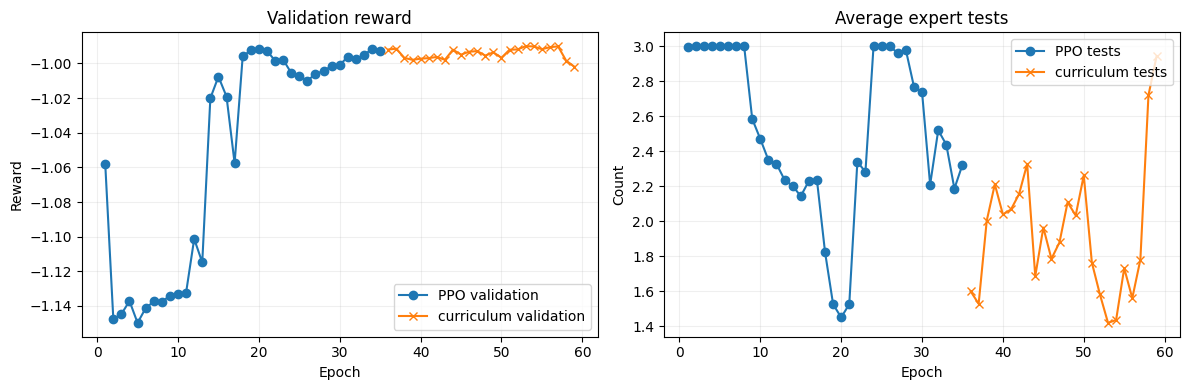

Held-out test actions:
mean tests: 1.411 | mean extensions: 1.889 | mean transforms: 0.174
All saved in: /content/drive/MyDrive/Aug26/Gym/skill_gym_full


In [ ]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
if ppo_history:
    history=pd.DataFrame(ppo_history)
    axes[0].plot(history.epoch,history.avg_reward,marker='o',label='PPO validation')
    axes[1].plot(history.epoch,history.avg_tests,marker='o',label='PPO tests')
if curr_history:
    h=pd.DataFrame(curr_history)
    offset=len(ppo_history)
    axes[0].plot(np.arange(len(h))+offset+1,h.avg_reward,marker='x',label='curriculum validation')
    axes[1].plot(np.arange(len(h))+offset+1,h.avg_tests,marker='x',label='curriculum tests')
axes[0].set(title='Validation reward',xlabel='Epoch',ylabel='Reward')
axes[1].set(title='Average expert tests',xlabel='Epoch',ylabel='Count')
for ax in axes:ax.legend();ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(ROOT/'plots'/'training_curves.png',dpi=160);plt.show()
print('Held-out test actions:')
print('mean tests:',round(pred_df.n_tests.mean(),3),
      '| mean extensions:',round(pred_df.n_extend.mean(),3),
      '| mean transforms:',round(pred_df.n_transform.mean(),3))
print('All saved in:',ROOT)